# connect to google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# import all packages

In [ ]:
%%capture
!pip install torchmetrics

In [ ]:
import pandas as pd
import numpy as np
import re
from torchmetrics import F1Score, Accuracy, Precision, Recall, ConfusionMatrix
from tensorflow.keras.preprocessing.text import Tokenizer
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch
import os
from collections import Counter
from itertools import groupby
from random import shuffle
from torch.nn.utils.rnn import pad_sequence
from collections import Counter
import matplotlib.pyplot as plt
from IPython.display import clear_output
import torch.nn.functional as F
from functools import partial
import math
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk import pos_tag
from nltk.stem import WordNetLemmatizer
import re
from enum import Enum
from typing import List, Optional, Tuple, Dict, Any, List, Union
from torch.autograd import Variable

In [ ]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

# Env Varaibles

In [ ]:
data_dir = "/content/drive/MyDrive/dataset_dir"
train_path = data_dir + "/train.txt"
val_path = data_dir + "/val.txt"
test_path = data_dir + "/test.txt"

contractions = {
    "aren't": "are not", "can't": "cannot", "couldn't": "could not", "didn't": "did not", "doesn't": "does not", "don't": "do not", "hadn't": "had not",
    "hasn't": "has not", "haven't": "have not", "he'd": "he would", "he'll": "he will", "he's": "he is", "how'd": "how did", "how'll": "how will",
    "how's": "how is", "i'd": "I would", "i'll": "I will", "i'm": "I am", "i've": "I have", "isn't": "is not", "it'd": "it would", "it'll": "it will",
    "it's": "it is", "let's": "let us", "ma'am": "madam", "mightn't": "might not", "mustn't": "must not", "o'clock": "of the clock", "shan't": "shall not", "she'd": "she would",
    "she'll": "she will", "she's": "she is", "should've": "should have", "shouldn't": "should not", "that's": "that is", "there's": "there is", "they'd": "they would", "they'll": "they will",
    "they're": "they are", "they've": "they have", "wasn't": "was not", "we'd": "we would", "we'll": "we will", "we're": "we are", "we've": "we have",
    "weren't": "were not", "what'll": "what will", "what're": "what are", "what's": "what is", "what've": "what have", "when's": "when is", "where'd": "where did", "where's": "where is",
    "where've": "where have", "who'll": "who will", "who's": "who is", "who've": "who have", "why's": "why is", "willn't": "will not", "won't": "will not",
    "would've": "would have", "wouldn't": "would not", "you'd": "you would", "you'll": "you will", "you're": "you are", "you've": "you have", "y'all": "you all",
    "ive": "i have", "youve": "you have", "yall": "you all", "dont": "do not", "doesnt": "does not", "havent": "have not", "hasnt": "has not",
    "isnt": "is not", "wasnt": "was not", "werent": "were not", "hadnt": "had not", "shant": "shall not", "mightnt": "might not", "mustnt": "must not",
    "neednt": "need not", "didnt": "did not", "im": "i am", "id": "i would", "youre": "you are", "hes": "he is", "shes": "she is", "its": "it is", "were": "we are",
    "theyre": "they are", "weve": "we have", "youll": "you will", "youd": "you would",
    "kinda": "kind of", "sorta": "sort of", "lemme": "let me", "dunno": "do not know",
}


more_stop_words = [
    'across', 'also', 'among', 'around', 'beside', 'besides', 'beyond', 'could', 'every', 'except', 'get', 'go', 'going', 'gone', 'got', 'keep', 'kept',
    'like', 'made', 'make', 'makes', 'many', 'much', 'near', 'one', 'per', 'since', 'take', 'taken', 'throughout', 'unless', 'upon', 'via', 'whenever',
    'whichever', 'within', 'without', 'would', 'yet',
]


not_stop_words = [
    "not", "no", "nor", "never", "none",                          # critical for reversing sentiment
    "what", "how", "why", "when", "where",                        # often imply surprise, doubt, or curiosity
    "but", "if", "because", "although", "though",                 # influence sentiment structure
]

lemmatizer = WordNetLemmatizer()

# Data Helpers

In [ ]:
def get_statistics(x_train_text, x_test_text, x_val_text):
    combined_texts = x_train_text + x_test_text + x_val_text
    lens = [len(text.split()) for text in combined_texts]
    vocab_size = len(set(" ".join(combined_texts).split()))
    max_len = max(lens)
    min_len = min(lens)

    word_freq = Counter(word for text in combined_texts for word in text.split())
    freq_values = list(word_freq.values())
    max_freq = max(freq_values)
    min_freq = min(freq_values)
    mean_freq = np.mean(freq_values)
    std_freq = np.std(freq_values)

    print("================================= Text Length Statistics =================================")
    print(f"Minimum text length         | {min_len} words")
    print(f"Maximum text length         | {max_len} words")
    print(f"Vocabulary size             | {vocab_size} unique words")
    print("==========================================================================================\n")

    print("================================ Word Frequency Statistics ================================")
    print(f"Most common word frequency  | {max_freq}")
    print(f"Least common word frequency | {min_freq}")
    print(f"Average word frequency      | {mean_freq:.2f}")
    print(f"Standard deviation          | {std_freq:.2f}")
    print("==========================================================================================")

def remove_less_freq_words(x_train_text, y_train_text, threshold=4):
    word_freq = Counter(word for text in x_train_text for word in text.split())

    x_train_text_new, y_train_text_new = [], []

    for text, label in zip(x_train_text, y_train_text):
        filtered_text = ' '.join(word for word in text.split() if word_freq[word] > threshold)
        if filtered_text:
            x_train_text_new.append(filtered_text)
            y_train_text_new.append(label)

    return x_train_text_new, y_train_text_new

# simple script to clean text from potentiel errors
def clean_text(text):
    text = re.sub(r'[^\w\s.,!?\'\";:()-]', '', text)  # remove special characters
    text = text.lower().strip()                       # lower and strip
    return text

# load text and extract inpu/output text
def load_file(file_path):
    x, y = [], []
    with open(file_path, "r") as f:
        lines = f.readlines()
        for line in lines:
            line = line.split(";")
            s = clean_text(" ".join(line[:-1]))
            t = clean_text(line[-1])
            x.append(s)
            y.append(t)

    return x, y

def compile_contractions(contractions):
    pattern = re.compile(r'\b(' + '|'.join(map(re.escape, contractions.keys())) + r')\b')
    return pattern
contractions_re = compile_contractions(contractions)

def expand_contractions(text, contractions, contractions_re):
    return contractions_re.sub(lambda x: contractions[x.group(0)], text)

def clean_text(text):
    text = re.sub(r"[^a-zA-Z0-9\s.,!?;:]", "", text)
    return text.lower().strip()

def simplify_text(text, more_stop_words, not_stop_words, contractions, contractions_re):
    text = expand_contractions(text, contractions, contractions_re)
    text = clean_text(text)

    stop_words = set(stopwords.words("english")).union(more_stop_words) - set(not_stop_words)

    words = word_tokenize(text)
    filtered_words = [
        word for word, pos in pos_tag(words)
        if word in ".,!?;:" or (word not in stop_words and pos.startswith(('J', 'R', 'N', 'V', 'MD')))
    ]

    lemm_words = [
        lemmatizer.lemmatize(word) if word not in ".,!?;:" else word
        for word in filtered_words
    ]

    lemm_words = [word for word in lemm_words if word.strip() and word]

    return " ".join(lemm_words)

def filter_texts(texts, labels, more_stop_words, not_stop_words, contractions, contractions_re):
    f_texts = []
    f_labels = []
    for t, l in zip(texts, labels):
        s_t = simplify_text(t, more_stop_words, not_stop_words, contractions, contractions_re)
        if s_t.strip():
            f_texts.append(s_t)
            f_labels.append(l)
    return f_texts, f_labels

# load data

In [ ]:
x_train_text, y_train_text = load_file(train_path)
x_test_text, y_test_text = load_file(test_path)
x_val_text, y_val_text = load_file(val_path)

# checking the results
print(len(x_train_text), len(x_test_text), len(x_val_text))
print(len(y_train_text), len(y_test_text), len(y_val_text))

for i in range(4):
    print(y_train_text[i], "===> ", x_train_text[i])

16000 2000 2000
16000 2000 2000
sadness ===>  i didnt feel humiliated
sadness ===>  i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake
anger ===>  im grabbing a minute to post i feel greedy wrong
love ===>  i am ever feeling nostalgic about the fireplace i will know that it is still on the property


In [ ]:
get_statistics(x_train_text, x_test_text, x_val_text)

================================= Text Length Statistics =================================
Minimum text length         | 2 words
Maximum text length         | 66 words
Vocabulary size             | 17096 unique words

================================ Word Frequency Statistics ================================
Most common word frequency  | 32242
Least common word frequency | 1
Average word frequency      | 22.39
Standard deviation          | 346.36


In [ ]:
x_train_text, y_train_text = remove_less_freq_words(x_train_text, y_train_text, threshold=3)
x_test_text, y_test_text = remove_less_freq_words(x_test_text, y_test_text, threshold=1)
x_val_text, y_val_text = remove_less_freq_words(x_val_text, y_val_text, threshold=1)

In [ ]:
get_statistics(x_train_text, x_test_text, x_val_text)

================================= Text Length Statistics =================================
Minimum text length         | 1 words
Maximum text length         | 63 words
Vocabulary size             | 4504 unique words

================================ Word Frequency Statistics ================================
Most common word frequency  | 32242
Least common word frequency | 2
Average word frequency      | 80.33
Standard deviation          | 671.40


# Applying Lemmatization and Stop Word Removal to Shorten Context for RNNs


In [ ]:
x_train_text, y_train_text = filter_texts(x_train_text, y_train_text, more_stop_words, not_stop_words, contractions, contractions_re)
x_test_text, y_test_text = filter_texts(x_test_text, y_test_text, more_stop_words, not_stop_words, contractions, contractions_re)
x_val_text, y_val_text = filter_texts(x_val_text, y_val_text, more_stop_words, not_stop_words, contractions, contractions_re)

In [ ]:
get_statistics(x_train_text, x_test_text, x_val_text)

================================= Text Length Statistics =================================
Minimum text length         | 1 words
Maximum text length         | 28 words
Vocabulary size             | 3859 unique words

================================ Word Frequency Statistics ================================
Most common word frequency  | 14354
Least common word frequency | 1
Average word frequency      | 38.51
Standard deviation          | 272.00


In [ ]:
for i in range(0, 20):
    print(y_train_text[i], "===> ", x_train_text[i])

sadness ===>  not feel humiliated
sadness ===>  feeling hopeless damned hopeful someone care awake
anger ===>  grabbing minute post feel greedy wrong
love ===>  ever feeling nostalgic know still property
anger ===>  feeling grouchy
sadness ===>  feeling little burdened lately not sure
surprise ===>  taking time amount fallen asleep lot faster feel funny
fear ===>  feel confused life teenager jaded year old man
joy ===>  year feel well huge
love ===>  feel romantic
sadness ===>  feel suffering seeing mean something
joy ===>  feel running divine experience expect type spiritual encounter
anger ===>  think time year feel dissatisfied
sadness ===>  feel low energy
joy ===>  sympathy general point possible writer trying find time write corner life sign agent let alone publishing contract feel little precious
joy ===>  not feel reassured anxiety side
sadness ===>  not really feel embarrassed
sadness ===>  feel pretty pathetic time
sadness ===>  started feeling sentimental child began collect

# label encoding

In [ ]:
class_cat = ['sadness', 'surprise', 'anger', 'love', 'joy', 'fear']  # list(set(y_train_text))
y_train = [class_cat.index(i) if i in class_cat else "<OOV>" for i in y_train_text]
y_test = [class_cat.index(i) if i in class_cat else "<OOV>" for i in y_test_text]
y_val = [class_cat.index(i) if i in class_cat else "<OOV>" for i in y_val_text]

n_class = len(class_cat)
print(f"number of classes: {n_class}")
print(f"class_cat: {class_cat}")
print(y_train_text[:10])
print(y_train[:10])

number of classes: 6
class_cat: ['sadness', 'surprise', 'anger', 'love', 'joy', 'fear']
['sadness', 'sadness', 'anger', 'love', 'anger', 'sadness', 'surprise', 'fear', 'joy', 'love']
[0, 0, 2, 3, 2, 0, 1, 5, 4, 3]


# With OneHot encoding

#### Zero Tokinezer ( text --> list of int )

In [ ]:
class ZeroTokenizer:
    def __init__(
        self,
        num_words=None,
        filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n',
        lower=True,
        split=" ",
        char_level=False,
        oov_token="<OOV>"):

        self.pad_id = 0
        self.oov_id = 1

        self.inter_tokenizer = Tokenizer(
            num_words=num_words,
            filters=filters,
            lower=lower,
            split=split,
            char_level=char_level,
            oov_token=oov_token
        )

    def fit(self, texts):
        self.inter_tokenizer.fit_on_texts(texts)

    def encode(self, text):
        encoded_seq = self.inter_tokenizer.texts_to_sequences([text])
        return encoded_seq[0]

    def decode(self, sequence):
        decoded_text = ' '.join([self.inter_tokenizer.index_word.get(i, "<OOV>") for i in sequence])
        return decoded_text

    def get_word_index(self):
        return self.inter_tokenizer.word_index

    def get_index_word(self):
        return self.inter_tokenizer.index_word

# our simple tokenizer health check :)
tokenizer = ZeroTokenizer(num_words=3000)
tokenizer.fit(x_train_text)

encoded_seq = tokenizer.encode("test simple test ismail")
decoded_text = tokenizer.decode(encoded_seq)

print("Encoded:", encoded_seq)
print("Decoded:", decoded_text)

Encoded: [1080, 878, 1080, 1]
Decoded: test simple test <OOV>


#### Zero Data Loader

In [ ]:
class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, min_len, max_len):
        self.data = [
            (self.truncate(tokenizer.encode(text), max_len), label)
            for text, label in zip(texts, labels)
            if min_len <= len(tokenizer.encode(text))
        ]
    def truncate(self, idx, max_len):
        return idx[:max_len] if len(idx) > max_len else idx

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x, y = self.data[idx]
        return x, y


def pad_collate_fn(bch, tokenizer, max_len):
    (idx, lbl) = zip(*bch)

    pad = [
        i + [tokenizer.pad_id] * (max_len - len(i)) if len(i) < max_len else i
        for i in idx
    ]

    pad = torch.LongTensor(pad)
    lbl = torch.LongTensor(lbl)

    return pad, lbl


# let's test our dataloader
tokenizer = ZeroTokenizer(num_words=3000)
tokenizer.fit(x_train_text)

# data loader
max_len = 20
dataset = TextDataset(x_train_text, y_train, tokenizer, min_len=3, max_len=max_len)

data_loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=partial(pad_collate_fn, tokenizer=tokenizer, max_len=max_len))

In [ ]:
# Test the data loader by printing the first batch
for x, y in data_loader:
    print("x :", x.shape)
    print("y :", y.shape)
    print(f"min, max : {x.min()}, {x.max()}")
    break

x : torch.Size([32, 20])
y : torch.Size([32])
min, max : 0, 2925


#### Quick analysis to our data to help decide what are the best data parameters to use to train our models

28
1


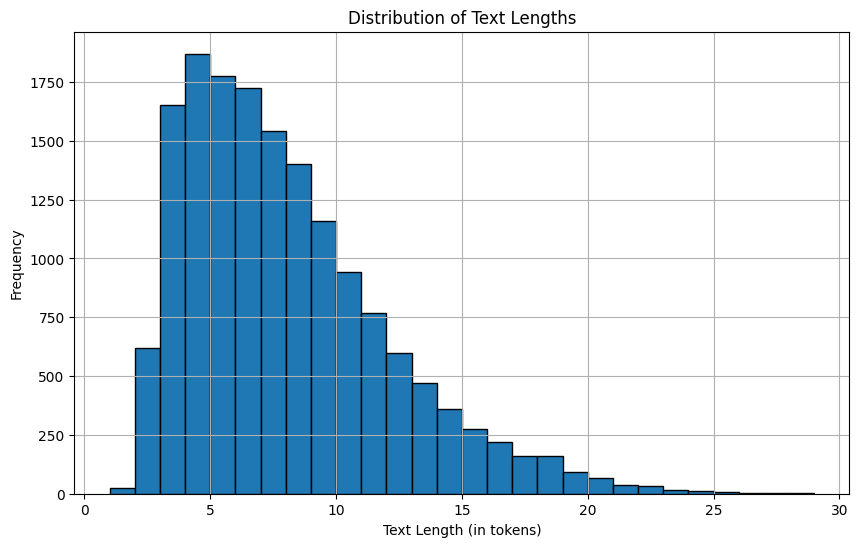

In [ ]:
txt_lens = [len(tokenizer.encode(text)) for text in x_train_text]
print(max(txt_lens))
print(min(txt_lens))

plt.figure(figsize=(10, 6))
plt.hist(txt_lens, bins=range(min(txt_lens), max(txt_lens) + 2), edgecolor='black')
plt.title('Distribution of Text Lengths')
plt.xlabel('Text Length (in tokens)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [ ]:
# first, let's check how many words we have in the train text
unique_words = set()
for text in x_train_text:
    unique_words.update(text.split())

print("Number of unique words:", len(unique_words))

Number of unique words: 3559


# Training Helpers

##### Data parameters and Init Tokenizer, Data loaders

In [ ]:
# Data Parameters
v_size = 3100 # 3000
max_seq_len = 20
min_seq_len = 3
b_size = 64

In [ ]:
# Tokenizer / fit
tokenizer = ZeroTokenizer(num_words=v_size)
tokenizer.fit(x_train_text)

# train
train_dataset = TextDataset(x_train_text, y_train, tokenizer, min_len=min_seq_len, max_len=max_seq_len)
train_loader = DataLoader(
    train_dataset,
    batch_size=b_size,
    shuffle=True,
    collate_fn=partial(pad_collate_fn, tokenizer=tokenizer, max_len=max_seq_len))

# val
val_dataset = TextDataset(x_val_text, y_val, tokenizer, min_len=min_seq_len, max_len=max_seq_len)
val_loader = DataLoader(
    val_dataset,
    batch_size=b_size,
    shuffle=True,
    collate_fn=partial(pad_collate_fn, tokenizer=tokenizer, max_len=max_seq_len))

# test
test_dataset = TextDataset(x_test_text, y_test, tokenizer, min_len=min_seq_len, max_len=max_seq_len)
test_loader = DataLoader(
    test_dataset,
    batch_size=b_size,
    shuffle=True,
    collate_fn=partial(pad_collate_fn, tokenizer=tokenizer, max_len=max_seq_len))

##### Training and Validation Helpers

In [ ]:
def validator(model, data_loader, criterion, n_step, device):
    model.eval()
    tot_loss = 0
    true_preds = 0
    tot_sample = 0

    with torch.no_grad():
        for step, (x, true_y) in enumerate(data_loader):
            x = x.to(device)
            true_y = true_y.to(device)

            # Forward pass
            logits = model(x)

            # loss / acc
            loss = criterion(logits, true_y)
            tot_loss += loss.item() * true_y.size(0)

            _, preds = torch.max(logits, 1) # val, idx
            true_preds += (preds == true_y).sum().item()
            tot_sample += true_y.size(0)

            if step >= n_step:
                break

    avg_loss = tot_loss   / tot_sample
    avg_acc  = true_preds / tot_sample
    return avg_loss, avg_acc

def trainer(model, data_loader, criterion, optimizer, n_step, max_norm=None, device="cpu"):
    model.train()
    tot_loss = 0
    true_preds = 0
    tot_sample = 0
    update_ratios = []

    for step, (x, true_y) in enumerate(data_loader):
        x, true_y = x.to(device), true_y.to(device)

        # Forward pass
        logits = model(x)

        # Calculate loss
        loss = criterion(logits, true_y)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()

        # update ratios before the optimizer step
        total_ratio = 0
        count_params_with_grad = 0
        for param in model.parameters():
            if param.grad is not None:
                param_scale = param.norm().item() if param.norm() != 0 else 1
                update_scale = (param.grad * -lr).norm().item()
                update_ratio = update_scale / param_scale
                total_ratio += update_ratio
                count_params_with_grad += 1

        # average ratio
        avg_ratio = total_ratio / count_params_with_grad if count_params_with_grad else 0
        update_ratios.append(avg_ratio)

        # Gradient clipping to prevent exploding gradients
        if max_norm:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)

        # optimization
        optimizer.step()

        # loss, acc
        tot_loss += loss.item() * true_y.size(0)
        _, preds = torch.max(logits, 1) # val, idx
        true_preds += (preds == true_y).sum().item()
        tot_sample += true_y.size(0)

        if step >= n_step:
            break

    avg_loss = tot_loss   / tot_sample
    avg_acc  = true_preds / tot_sample
    avg_up_ratio = sum(update_ratios) / len(update_ratios) if update_ratios else 0
    return avg_loss, avg_acc, avg_up_ratio

def tester(model, data_loader, criterion, n_step, device):
    model.eval()
    tot_loss = 0
    true_preds = 0
    tot_sample = 0
    precision_metric = Precision(task='multiclass', average='macro', num_classes=6).to(device)
    recall_metric = Recall(task='multiclass', average='macro', num_classes=6).to(device)
    f1_metric = F1Score(task='multiclass', average='macro', num_classes=6).to(device)
    confusion_matrix = ConfusionMatrix(task='multiclass', num_classes=6).to(device)

    with torch.no_grad():
        for step, (x, true_y) in enumerate(data_loader):
            x = x.to(device)
            true_y = true_y.to(device)

            # Forward pass
            logits = model(x)

            # Calculate loss and accumulate
            loss = criterion(logits, true_y)
            tot_loss += loss.item() * true_y.size(0)

            # Predictions
            _, preds = torch.max(logits, 1)
            true_preds += (preds == true_y).sum().item()
            tot_sample += true_y.size(0)

            # Update metrics
            precision_metric.update(preds, true_y)
            recall_metric.update(preds, true_y)
            f1_metric.update(preds, true_y)
            confusion_matrix.update(preds, true_y)

            if step >= n_step:
                break

    # Calculate average loss and accuracy
    avg_loss = tot_loss / tot_sample
    avg_acc = true_preds / tot_sample
    precision = precision_metric.compute().item()
    recall = recall_metric.compute().item()
    f1 = f1_metric.compute().item()
    conf_matrix = confusion_matrix.compute().cpu().numpy()

    print("\n" + "="*40)
    print(f"{' '*10}Test Results Summary")
    print("="*40)
    print(f"{'Metric':<20} | {'Value':>15}")
    print("-"*40)
    print(f"{'Average Loss':<20} | {avg_loss:>15.4f}")
    print(f"{'Accuracy':<20} | {avg_acc * 100:>14.2f}%")
    print(f"{'Precision':<20} | {precision:>15.4f}")
    print(f"{'Recall':<20} | {recall:>15.4f}")
    print(f"{'F1 Score':<20} | {f1:>15.4f}")
    print("="*40)

    # Display Confusion Matrix
    print("\nConfusion Matrix:")
    print("-"*60)
    print(" " * 5, end="")
    for i in range(conf_matrix.shape[1]):
        print(f"{i:^8}", end=" ")
    print("\n" + "-"*60)

    for i, row in enumerate(conf_matrix):
        print(f"{i:<5}", end="")
        for val in row:
            print(f"{val:^8}", end=" ")
        print()

    print("-"*60)


def live_plot_triple(data_dict, figsize=(18, 5), title="Model Training Progress"):
    clear_output(wait=True)
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=figsize)

    # Loss plot
    if "tr_loss_avg" in data_dict and data_dict["tr_loss_avg"]:
        ax1.plot(data_dict["tr_loss_avg"], "r-", label="Train Loss Avg", marker='o')
    if "vl_loss_avg" in data_dict and data_dict["vl_loss_avg"]:
        ax1.plot(data_dict["vl_loss_avg"], "b-", label="Val Loss Avg", marker='o')
    ax1.set_title("Training & Validation Loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc='upper left')
    ax1.grid(True)

    # Accuracy plot
    if "tr_acc_avg" in data_dict and data_dict["tr_acc_avg"]:
        ax2.plot(data_dict["tr_acc_avg"], "r--", label="Train Acc Avg", alpha=0.7, marker='x')
    if "vl_acc_avg" in data_dict and data_dict["vl_acc_avg"]:
        ax2.plot(data_dict["vl_acc_avg"], "b--", label="Val Acc Avg", alpha=0.7, marker='x')
    ax2.set_title("Training & Validation Accuracy")
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Accuracy (%)")
    ax2.legend(loc='upper right')
    ax2.grid(True)

    # Update Ratio plot
    ax3.axhline(y=0.001, color='r', linestyle='--', label='Reference (10^-3)')
    if "avg_up_ratio" in data_dict and data_dict["avg_up_ratio"]:
        ax3.plot(data_dict["avg_up_ratio"], "g-", label="Average Update Ratios", marker='^')
    ax3.set_title("Parameter Update Ratios")
    ax3.set_xlabel("Epochs")
    ax3.set_ylabel("Update Ratio")
    ax3.legend(loc='upper right')
    ax3.grid(True)

    fig.suptitle(title)
    plt.show()

def get_lr(epoch, lr, gamma, min_lr):
    d_lr = lr * (gamma ** epoch)
    return max(d_lr, min_lr)

def update_lr(optimizer: torch.optim.Optimizer, new_lr: float):
    for param_group in optimizer.param_groups:
        param_group["lr"] = new_lr

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# def get_lr(epoch, lr, gamma, min_lr):
#     d_lr = lr * (gamma ** epoch)
#     return max(d_lr, min_lr)

# # Initial learning rate
# lr = 1e-4
# min_lr = 1e-5
# gamma = 0.998
# n_epochs = 1000

# lrs = [get_lr(epoch, lr, gamma, min_lr) for epoch in range(n_epochs)]

# plt.figure(figsize=(10, 5))
# plt.plot(lrs, label='Learning Rate')
# plt.title('Learning Rate Decay Over Epochs')
# plt.xlabel('Epochs')
# plt.ylabel('Learning Rate')
# plt.legend()
# plt.grid(True)
# plt.show()

# RNN (PyTorch API nn.RNN)

In [ ]:
class OneHotPyRNN(nn.Module):
    def __init__(
        self, n_emb, h_dim, n_unit, v_size, n_class,
        act="relu", brnn=False, bias=True, d_rate=0.0, device="cpu"
    ):
        super(OneHotPyRNN, self).__init__()

        self.v_size = v_size
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.brnn = brnn
        self.n_emb = n_emb

        self.emb = nn.Linear(self.v_size, self.n_emb)

        self.rnn = nn.RNN(
            input_size=self.n_emb,
            hidden_size=self.h_dim,
            num_layers=self.n_unit,
            bias=bias,
            dropout=self.d_rate,
            batch_first=True,
            bidirectional=self.brnn,
            nonlinearity=act,
        )

        self.fc = nn.Sequential(
            nn.Linear(self.h_dim * 2 if self.brnn else self.h_dim, 2 * self.h_dim),
            nn.ReLU(),
            nn.Linear(2 * self.h_dim, self.n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = F.one_hot(x, num_classes=self.v_size).float().to(self.device)   # (b, t, v)
        x = self.emb(x)             # (b, t, e)
        _, hn = self.rnn(x)         # (b, t, h)

        if self.brnn:
            hn = hn.view(self.n_unit, 2, b, self.h_dim)  # (n_unit, 2, b, h)
            h_fwd = hn[-1, 0]                     # (b, h)
            h_bwd = hn[-1, 1]                     # (b, h)
            x = torch.cat((h_fwd, h_bwd), dim=1)  # (b, h*2)
        else:
            x = hn[-1, :, :]                      # (b, h)

        x = self.dropout(x)                       # (b, h or h*2)
        x = self.fc(x)                            # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = OneHotPyRNN(
    n_emb=100,
    h_dim=128,
    n_unit=2,
    v_size=3000,
    n_class=6,
    act="relu",
    d_rate=0.0,
    device="cpu",
    brnn=True,
    bias=True,
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 64
h_dim = 128
n_unit = 2
n_class = len(class_cat)
d_rate = 0.1
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 1e-2
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.98

# Training configuration
n_epoch = 100
n_step = 10

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = OneHotPyRNN(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    v_size=v_size,
    n_class=n_class,
    act="relu",
    d_rate=d_rate,
    device=device,
    brnn=True,
    bias=True,
)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

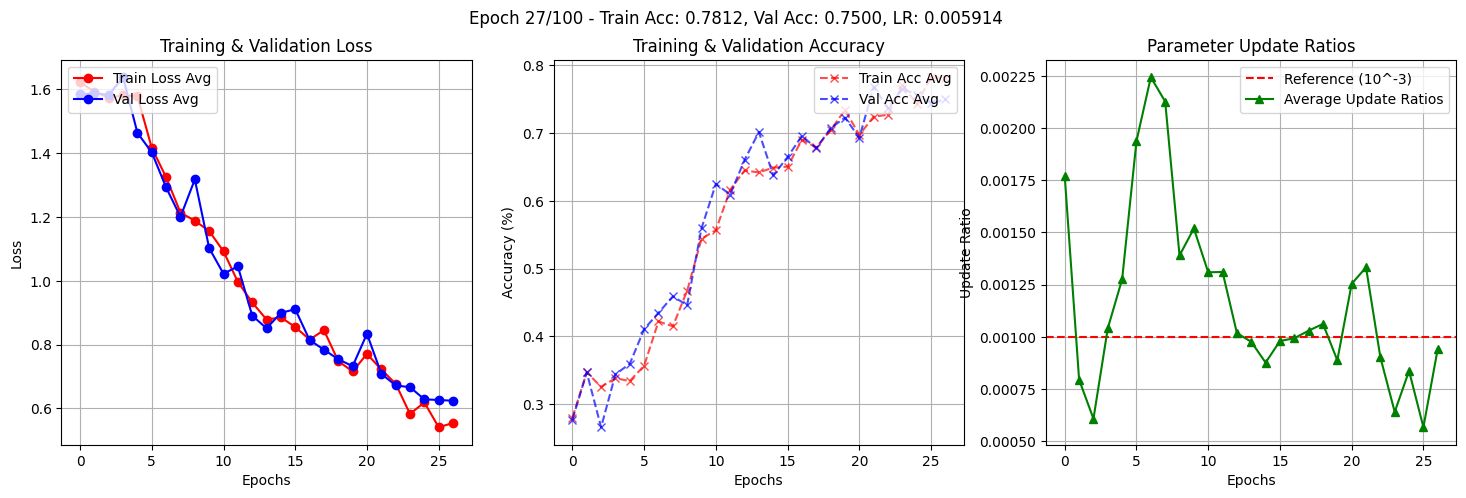

New best validation accuracy: 0.7827, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.78:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break


    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.5796
Accuracy             |          75.59%
Precision            |          0.5950
Recall               |          0.6121
F1 Score             |          0.5896

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      524       5        9        5        8        0     
1       2        8        41       9        5        0     
2       14       3        69       11       5       163    
3       11       4        5       115       16       0     
4       17       7        1        61      571       0     
5       8        2        46       4        2       150    
------------------------------------------------------------


# RNN ( Implementation From scratch )

In [ ]:
class RNN(nn.Module):
    def __init__(self, in_dim, h_dim, act='relu', bias = False, device = "cpu"):
        super(RNN, self).__init__()
        self.h_dim = h_dim
        self.device = device
        self.bias = bias

        self.i2h = nn.Linear(in_features=in_dim, out_features=h_dim, bias=bias, device=device)
        self.h2h = nn.Linear(in_features=h_dim, out_features=h_dim, bias=bias, device=device)

        if act == 'relu':
            self.act_fun = nn.ReLU()
        elif act == 'tanh':
            self.act_fun = nn.Tanh()
        else:
            raise ValueError("Unsupported activation function")

        self._init_params()

    def _init_params(self):
        for param in self.parameters():
            if param.dim() > 1:
                if isinstance(self.act_fun, nn.ReLU):     # Kaiming (He)
                    nn.init.kaiming_uniform_(param, nonlinearity='relu')
                elif isinstance(self.act_fun, nn.Tanh):   # Xavier (Glorot)
                    nn.init.xavier_uniform_(param)
            else:
                nn.init.constant_(param, 0)

    def forward(self, x, h=None):
        if h is None:
            h = torch.zeros(x.size(0), self.h_dim, device=x.device)

        h = self.act_fun(self.i2h(x) + self.h2h(h)) + h * 0.5    # residual connection with half informations works :)
        return h

In [ ]:
class RNNBlock(nn.Module):
    def __init__(self, in_dim, h_dim, n_unit, act='relu', bias = False, device = "cpu"):
        super(RNNBlock, self).__init__()
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device

        self.units = nn.ModuleList([
            RNN(in_dim=in_dim, h_dim=h_dim, act=act, bias=bias, device=device) for _ in range(n_unit)
            ])

    def forward(self, x, h=None):
        if x.shape[1] != self.n_unit:
            raise ValueError(f"Expected input sequence length of {self.n_unit}, but got {x.shape[1]}")

        for i, unit in enumerate(self.units):
            h = unit(x[:, i, :], h)

        return h

In [ ]:
class OneHotRNN(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, v_size, n_class, bias=True, d_rate=0.0, device="cpu"):
        super(OneHotRNN, self).__init__()

        self.v_size = v_size
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.n_emb = n_emb

        self.emb = nn.Linear(self.v_size, self.n_emb)

        self.rnn = RNNBlock(
            in_dim=self.n_emb,
            h_dim=self.h_dim,
            n_unit=self.n_unit,
            act="relu",
            bias=bias,
            device=device,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim, 2 * h_dim),
            nn.ReLU(),
            nn.Linear(2 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = F.one_hot(x, num_classes=self.v_size).float().to(self.device)   # (b, t, v)
        x = self.emb(x)    # (b, t, e)
        x = self.rnn(x)    # (b, t, h)

        x = self.dropout(x)  # (b, h or h*2)
        x = self.fc(x)       # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = OneHotRNN(
    n_emb=100,
    h_dim=128,
    n_unit=20,
    v_size=3000,
    n_class=6,
    bias=True,
    d_rate=0.3,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 100
h_dim = 128
n_unit = max_seq_len
n_class = len(class_cat)
d_rate = 0.3
max_norm = 5.0

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 4e-3
min_lr = 1e-5
betas = (0.99, 0.994)
alpha = 0.9
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.99

# Training configuration
n_epoch = 1000
n_step = 20
model_size = v_size
warmup_steps = 1000

# Early stopping parameters
patience = 60
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = OneHotRNN(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    v_size=v_size,
    n_class=n_class,
    bias=True,
    d_rate=d_rate,
    device=device,
)
model.to(device)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

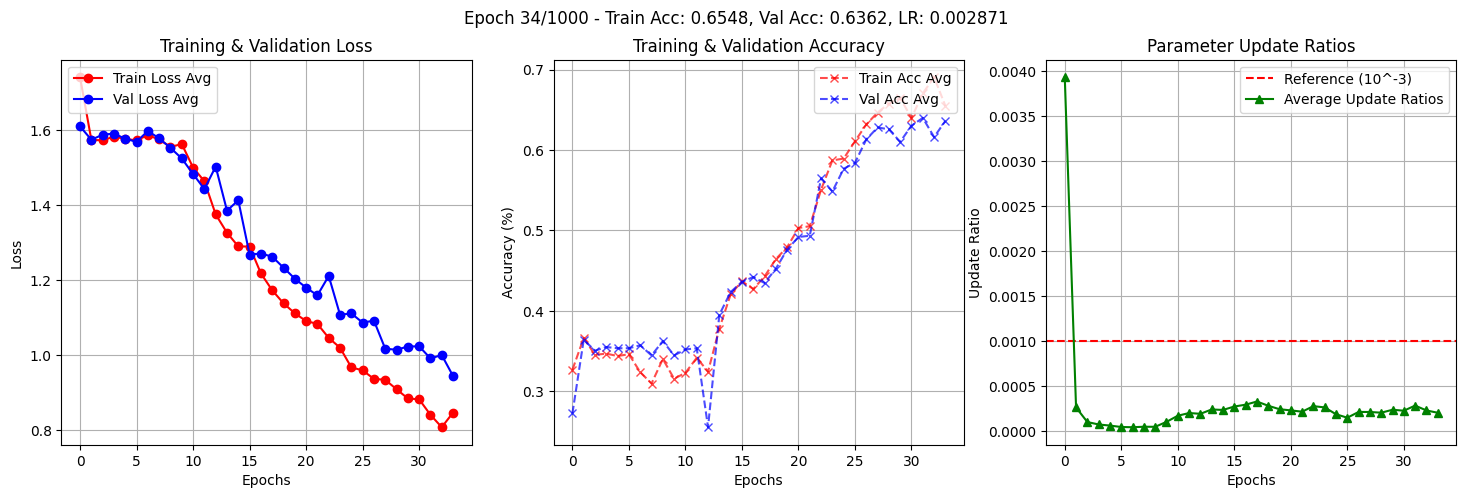

New best validation accuracy: 0.6518, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.65:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.8977
Accuracy             |          67.02%
Precision            |          0.3326
Recall               |          0.4299
F1 Score             |          0.3646

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      495       0        23       0        33       0     
1       9        0        54       0        2        0     
2       42       0       220       0        3        0     
3       47       0        95       0        9        0     
4       91       0        7        0       559       0     
5       24       0       187       0        1        0     
------------------------------------------------------------


# LSTM (PyTorch API nn.LSTM)

In [ ]:
class OneHotPyLSTM(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, v_size, n_class, brnn=False, bias=True, d_rate=0.0, device="cpu"):
        super(OneHotPyLSTM, self).__init__()

        self.v_size = v_size
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.brnn = brnn
        self.n_emb = n_emb

        self.emb = nn.Linear(self.v_size, self.n_emb)

        self.rnn = nn.LSTM(
            input_size=self.n_emb,
            hidden_size=self.h_dim,
            num_layers=self.n_unit,
            bias=bias,
            dropout=self.d_rate,
            batch_first=True,
            bidirectional=self.brnn,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim * 2 if brnn else h_dim, 2 * h_dim),
            nn.ReLU(),
            nn.Linear(2 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.constant_(module.bias, 0)
        elif isinstance(module, nn.LSTM):
            for name, param in module.named_parameters():
                if 'weight_ih' in name:
                    nn.init.xavier_uniform_(param)
                elif 'weight_hh' in name:
                    nn.init.orthogonal_(param)
                elif 'bias' in name:
                    with torch.no_grad():
                        param.fill_(0)
                        n = param.size(0)
                        param[n // 4:n // 2].fill_(1)

    def forward(self, x):
        b, t = x.shape
        x = F.one_hot(x, num_classes=self.v_size).float().to(self.device)   # (b, t, v)
        x = self.emb(x)             # (b, t, e)
        _, (hn, _) = self.rnn(x)    # (b, t, h)

        if self.brnn:
            hn = hn.view(self.n_unit, 2, b, self.h_dim)  # (n_unit, 2, b, h)
            h_fwd = hn[-1, 0]                     # (b, h)
            h_bwd = hn[-1, 1]                     # (b, h)
            x = torch.cat((h_fwd, h_bwd), dim=1)  # (b, h*2)
        else:
            x = hn[-1, :, :]                      # (b, h)

        x = self.dropout(x)                       # (b, h or h*2)
        x = self.fc(x)                            # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = OneHotPyLSTM(
    n_emb=100,
    h_dim=128,
    n_unit=2,
    v_size=3000,
    n_class=6,
    brnn=True,
    bias=True,
    d_rate=0.4,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 64
h_dim = 128
n_unit = 2
n_class = len(class_cat)
d_rate = 0.0
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 1e-2
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.98

# Training configuration
n_epoch = 100
n_step = 10

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = OneHotPyLSTM(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    v_size=v_size,
    n_class=n_class,
    brnn=True,
    bias=True,
    d_rate=d_rate,
    device=device,
)
model.to(device)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

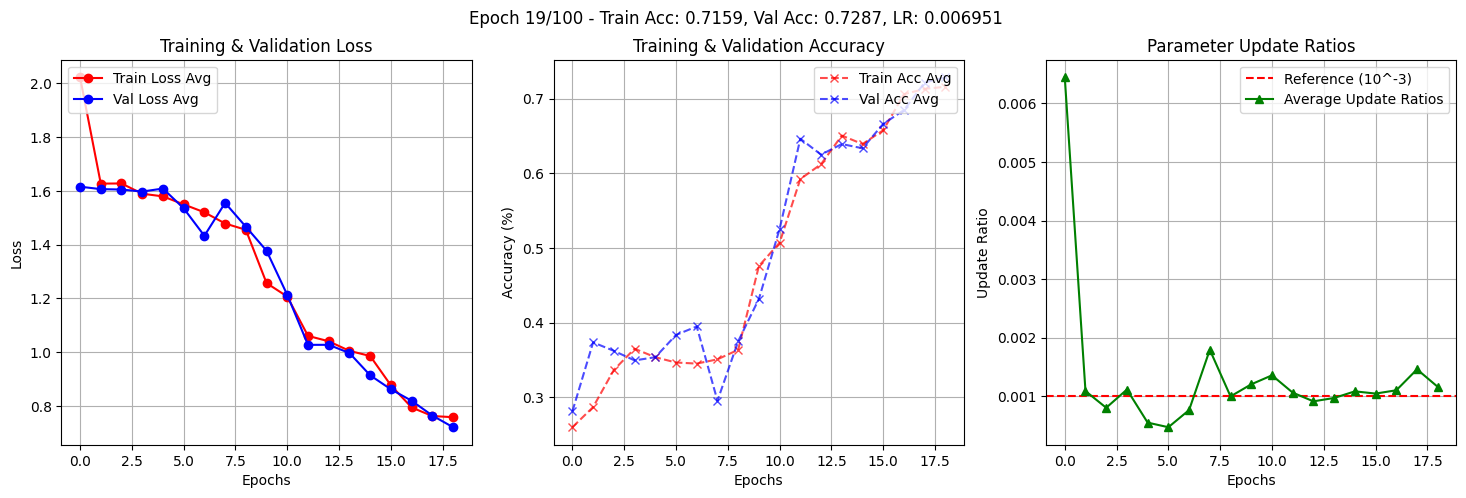

New best validation accuracy: 0.8054, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience
        torch.save(model.state_dict(), best_model_path)
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.78:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break

    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.6312
Accuracy             |          78.75%
Precision            |          0.6025
Recall               |          0.6074
F1 Score             |          0.5886

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      493       0        8        24       26       0     
1       2        0        22       38       3        0     
2       4        0       201       27       7        26    
3       6        0        3       100       42       0     
4       9        0        1        25      622       0     
5       6        0        99       20       6        81    
------------------------------------------------------------


# LSTM ( Implementation From scratch )

In [ ]:
class LSTM(nn.Module):
    def __init__(self, in_dim, h_dim, is_res=True, bias = False, device = 'cpu'):
        super(LSTM, self).__init__()
        self.in_dim = in_dim
        self.h_dim = h_dim
        self.bias = bias
        self.is_res = is_res
        self.device = device

        self.i2h = nn.Linear(in_dim, h_dim * 4, bias=bias).to(device)    # [b, s, 4*o]
        self.h2h = nn.Linear(h_dim, h_dim * 4, bias=bias).to(device)   # [b, o, 4*o]

        if is_res:
            self.res_proj = nn.Linear(in_dim, h_dim, bias=bias)
        else:
            self.res_proj = None

        self.init_parameters()
        self.to(device)

    def init_parameters(self):
        std = 1.0 / torch.sqrt(torch.tensor(self.in_dim, dtype=torch.float))
        for w in self.parameters():
            w.data.uniform_(-std, std)

    def forward(self, x, xh = None):
        if xh is None:
            xh = Variable(x.new_zeros(x.size(0), self.h_dim))  # [b, o]
            xh = (xh, xh)

        xh, xc = xh

        gts = self.i2h(x) + self.h2h(xh)                # [b, s, 4*o]
        igt, fgt, cgt, ogt = gts.chunk(4, 1)            # gts ==> [i, f, c, o]

        i = torch.sigmoid(igt)                          # [b, s, o]
        f = torch.sigmoid(fgt)                          # [b, s, o]
        g = torch.tanh(cgt)                             # [b, s, o]
        o = torch.sigmoid(ogt)                          # [b, s, o]

        yc = xc * f + i * g                             # [b, s, o]
        yh = o * torch.tanh(yc)                         # [b, s, o]

        if self.res_proj:
            yh = yh + self.res_proj(x) * 0.6

        return (yh, yc)

In [ ]:
class LSTMBlock(nn.Module):
    def __init__(self, in_dim, h_dim, n_unit, is_res=True, bias = False, device = "cpu"):
        super(LSTMBlock, self).__init__()
        self.in_dim = in_dim
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device

        self.units = nn.ModuleList([LSTM(in_dim=in_dim, h_dim=h_dim, is_res=is_res, bias=bias, device=device) for _ in range(n_unit)])

    def forward(self, x, xh = None):
        b, s, _ = x.shape   # [b, s, e]

        if xh is None:
            h0: torch.Tensor = Variable(torch.zeros(self.n_unit, b, self.h_dim, device=self.device))            # [s, b, o]
        else:
            h0: torch.Tensor = xh                                                                                 # [s, b, o]

        xhs: List[Tuple[torch.Tensor, torch.Tensor]] = [(h0[u, :, :], h0[u, :, :]) for u in range(self.n_unit)]

        for i in range(s):
            chr = x[:, i, :]                            # [b, e]
            unit = self.units[i]                        # one LSTM unit
            xhs[i] = None if i == 0 else xhs[i - 1]
            uh = unit(chr, xhs[i])                      # [b, h], [b, h]
            xhs[i] = uh

        return uh[0]

In [ ]:
class OneHotLSTM(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, v_size, n_class, bias=True, d_rate=0.0, device="cpu"):
        super(OneHotLSTM, self).__init__()

        self.v_size = v_size
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.n_emb = n_emb

        self.emb = nn.Linear(self.v_size, self.n_emb)

        self.rnn = LSTMBlock(
            in_dim=self.n_emb,
            h_dim=self.h_dim,
            n_unit=self.n_unit,
            bias=bias,
            device=self.device,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim, 2 * h_dim),
            nn.ReLU(),
            nn.Linear(2 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = F.one_hot(x, num_classes=self.v_size).float().to(self.device)   # (b, t, v)
        x = self.emb(x)    # (b, t, e)
        x = self.rnn(x)    # (b, t, h)

        x = self.dropout(x)  # (b, h or h*2)
        x = self.fc(x)       # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = OneHotLSTM(
    n_emb=100,
    h_dim=128,
    n_unit=20,
    v_size=3000,
    n_class=6,
    bias=True,
    d_rate=0.4,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 100
h_dim = 128
n_unit = max_seq_len
n_class = len(class_cat)
d_rate = 0.2
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 2e-3
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.99

# Training configuration
n_epoch = 400
n_step = 20

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = OneHotLSTM(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    v_size=v_size,
    n_class=n_class,
    bias=True,
    d_rate=d_rate,
    device=device,
)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

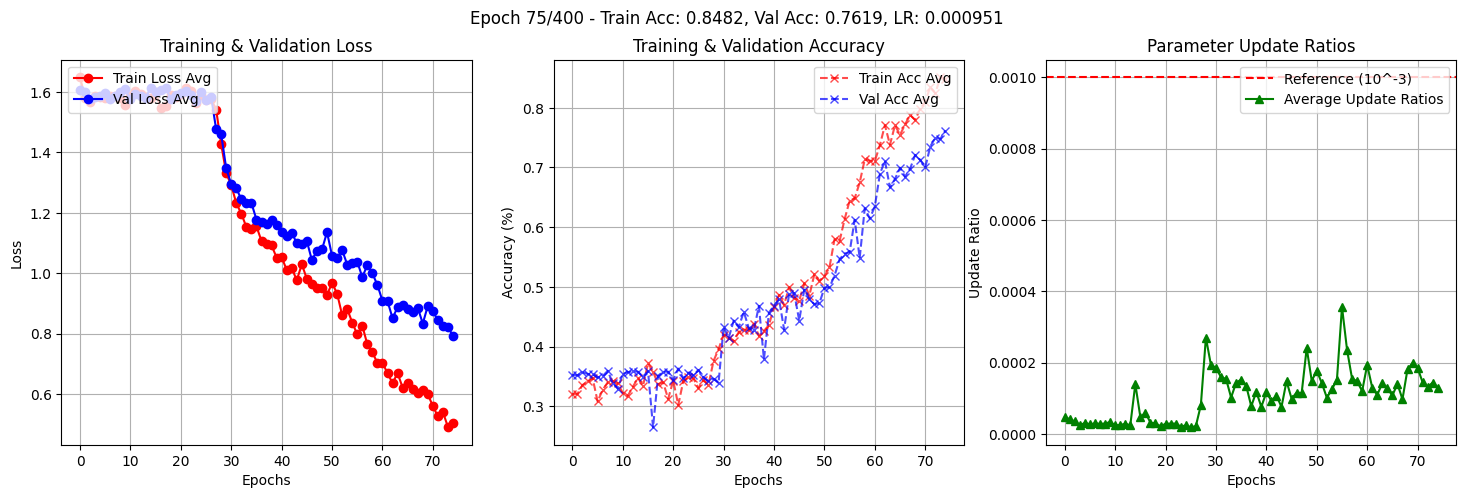

New best validation accuracy: 0.7753, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.77:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break


    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.7730
Accuracy             |          76.28%
Precision            |          0.6530
Recall               |          0.6595
F1 Score             |          0.6505

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      418       7        1        57       53       15    
1       9        13       0        12       3        28    
2       14       4       201       11       3        32    
3       34       8        2        98       6        3     
4       47       2        0        43      565       0     
5       7        18       21       11       0       155    
------------------------------------------------------------


# GRU (PyTorch API nn.GRU)

In [ ]:
class OneHotPyGRU(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, v_size, n_class, brnn=False, bias=True, d_rate=0.0, device="cpu"):
        super(OneHotPyGRU, self).__init__()

        self.v_size = v_size
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.brnn = brnn
        self.n_emb = n_emb

        self.emb = nn.Linear(self.v_size, self.n_emb)

        self.rnn = nn.GRU(
            input_size=self.n_emb,
            hidden_size=self.h_dim,
            num_layers=self.n_unit,
            bias=bias,
            dropout=self.d_rate,
            batch_first=True,
            bidirectional=self.brnn,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim * 2 if brnn else h_dim, 2 * h_dim),
            nn.ReLU(),
            nn.Linear(2 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.constant_(module.bias, 0)
        elif isinstance(module, nn.LSTM):
            for name, param in module.named_parameters():
                if 'weight_ih' in name:
                    nn.init.xavier_uniform_(param)
                elif 'weight_hh' in name:
                    nn.init.orthogonal_(param)
                elif 'bias' in name:
                    with torch.no_grad():
                        param.fill_(0)
                        n = param.size(0)
                        param[n // 4:n // 2].fill_(1)

    def forward(self, x):
        b, t = x.shape
        x = F.one_hot(x, num_classes=self.v_size).float().to(self.device)   # (b, t, v)
        x = self.emb(x)             # (b, t, e)
        _, hn = self.rnn(x)    # (b, t, h)

        if self.brnn:
            hn = hn.view(self.n_unit, 2, b, self.h_dim)  # (n_unit, 2, b, h)
            h_fwd = hn[-1, 0]                     # (b, h)
            h_bwd = hn[-1, 1]                     # (b, h)
            x = torch.cat((h_fwd, h_bwd), dim=1)  # (b, h*2)
        else:
            x = hn[-1, :, :]                      # (b, h)

        x = self.dropout(x)                       # (b, h or h*2)
        x = self.fc(x)                            # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = OneHotPyGRU(
    n_emb=100,
    h_dim=128,
    n_unit=2,
    v_size=3000,
    n_class=6,
    brnn=True,
    bias=True,
    d_rate=0.4,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 64
h_dim = 128
n_unit = 2
n_class = len(class_cat)
d_rate = 0.1
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 1e-2
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.98

# Training configuration
n_epoch = 100
n_step = 10

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = OneHotPyGRU(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    v_size=v_size,
    n_class=n_class,
    brnn=True,
    bias=True,
    d_rate=d_rate,
    device=device
)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

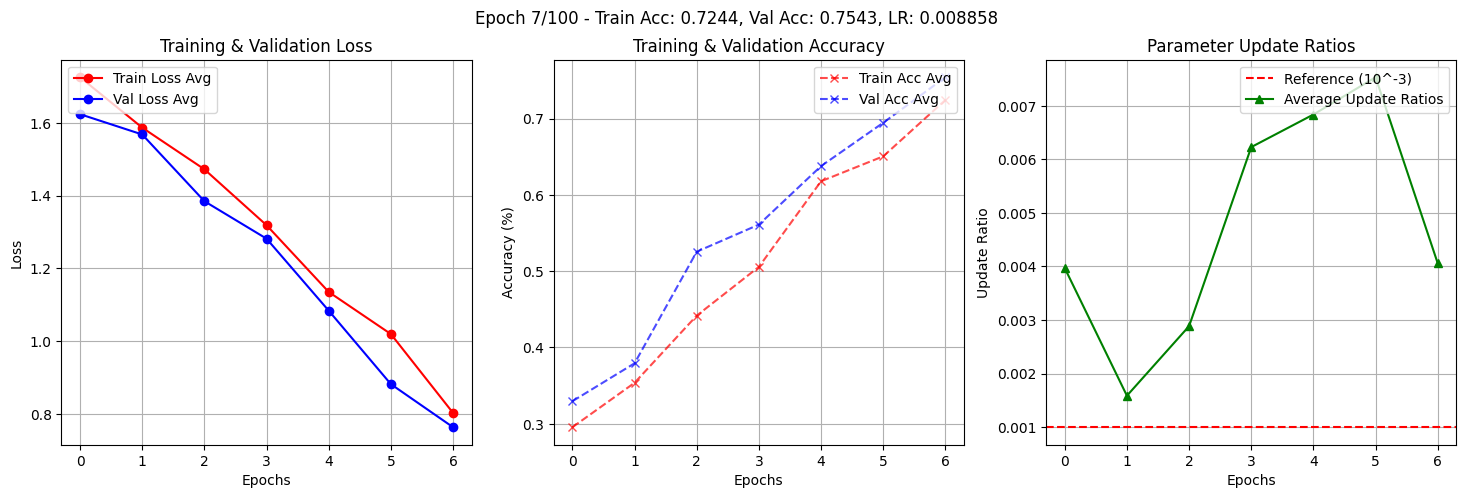

New best validation accuracy: 0.8082, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.78:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break


    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.6339
Accuracy             |          81.54%
Precision            |          0.6818
Recall               |          0.6398
F1 Score             |          0.6310

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      478       0        17       11       32       13    
1       3        1        5        11       13       32    
2       11       0       221       7        15       11    
3       3        1        12       44       86       5     
4       3        1        13       19      617       4     
5       5        0        9        3        6       189    
------------------------------------------------------------


# GRU ( Implementation From scratch )

In [ ]:
class GRU(nn.Module):
    def __init__(self, in_dim, h_dim, is_res=True, bias = False, device = 'cpu'):
        super(GRU, self).__init__()
        self.in_dim = in_dim
        self.h_dim = h_dim
        self.bias = bias
        self.device = device
        self.is_res = is_res

        self.i2h = nn.Linear(in_dim, 3 * h_dim, bias=bias).to(device)    # [b, s, 3 x o]
        self.h2h = nn.Linear(h_dim, 3 * h_dim, bias=bias).to(device)   # [b, o, 3 x o]

        if self.is_res:
            self.res_proj = nn.Linear(in_dim, h_dim, bias=bias).to(device)
        else:
            self.res_proj = None

        self.init_parameters()
        self.to(device)

    def init_parameters(self):
        std = 1.0 / torch.sqrt(torch.tensor(self.in_dim, dtype=torch.float))
        for w in self.parameters():
            w.data.uniform_(-std, std)

    def forward(self, x, h = None):
        if h is None:
            h = Variable(x.new_zeros(x.size(0), self.h_dim))  # [b, o]

        gts = self.i2h(x) + self.h2h(h)                         # [b, s, 3*o]

        gts = self.i2h(x) + self.h2h(h)                         # [b, s, 3*o]
        rgt, zgt, hgt = gts.chunk(3, 1)                         # gts ==> [r, z, h]

        r = torch.sigmoid(rgt)                                  # [b, s, o]
        z = torch.sigmoid(zgt)                                  # [b, s, o]
        g = torch.tanh(r * hgt + (1 - r) * h)                   # [b, s, o]

        h = (1 - z) * h + z * g                                 # [b, s, o]

        if self.is_res:
            h = h + self.res_proj(x)

        return h

In [ ]:
class GRUBlock(nn.Module):
    def __init__(self, in_dim, h_dim, n_unit, bias=False, device="cpu"):
        super(GRUBlock, self).__init__()
        self.in_dim = in_dim
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device

        self.units = nn.ModuleList([GRU(in_dim=in_dim, h_dim=h_dim, bias=bias, device=device) for _ in range(n_unit)])

    def forward(self, x, xh = None):
        b, s, _ = x.shape   # [b, s, e]

        if xh is None:
            h0: torch.Tensor = Variable(torch.zeros(self.n_unit, b, self.h_dim, device=self.device))            # [s, b, o]
        else:
            h0: torch.Tensor = xh                                                                                 # [s, b, o]

        xhs: List[Tuple[torch.Tensor, torch.Tensor]] = [(h0[u, :, :], h0[u, :, :]) for u in range(self.n_unit)]

        for i in range(s):
            chr = x[:, i, :]                            # [b, e]
            unit = self.units[i]                        # one LSTM unit

            xhs[i] = None if i == 0 else xhs[i - 1]
            h = unit(chr, xhs[i])                       # [b, h], [b, h]
            xhs[i] = h

        return h

In [ ]:
class OneHotGRU(nn.Module):
    def __init__(self, n_emb, h_dim, n_unit, v_size, n_class, bias=True, d_rate=0.0, device="cpu"):
        super(OneHotGRU, self).__init__()

        self.v_size = v_size
        self.h_dim = h_dim
        self.n_unit = n_unit
        self.device = device
        self.d_rate = d_rate
        self.n_class = n_class
        self.n_emb = n_emb

        self.emb = nn.Linear(self.v_size, self.n_emb)

        self.rnn = GRUBlock(
            in_dim=self.n_emb,
            h_dim=self.h_dim,
            n_unit=self.n_unit,
            bias=bias,
            device=self.device,
        )

        self.fc = nn.Sequential(
            nn.Linear(h_dim, 2 * h_dim),
            nn.ReLU(),
            nn.Linear(2 * h_dim, n_class),
        )

        self.dropout = nn.Dropout(self.d_rate)

    def forward(self, x):
        b, t = x.shape
        x = F.one_hot(x, num_classes=self.v_size).float().to(self.device)   # (b, t, v)
        x = self.emb(x)    # (b, t, e)
        x = self.rnn(x)    # (b, t, h)
        x = self.dropout(x)  # (b, h or h*2)
        x = self.fc(x)       # (b, n_class)
        return x

# test
x = torch.randint(0, 3000, (16, 20))

model = OneHotGRU(
    n_emb=100,
    h_dim=128,
    n_unit=20,
    v_size=3000,
    n_class=6,
    bias=True,
    d_rate=0.4,
    device="cpu",
)

print(f"x.shape : {x.shape}")
o = model(x)
print(f"o.shape : {o.shape}")

x.shape : torch.Size([16, 20])
o.shape : torch.Size([16, 6])


In [ ]:
# Device configuration
device = "cuda" if torch.cuda.is_available() else "cpu"

# Model hyperparameters
n_emb = 100
h_dim = 128
n_unit = max_seq_len
n_class = len(class_cat)
d_rate = 0.1
max_norm = 5

# Label smoothing
smoothing = 0.01

# Optimizer configuration
lr = 2e-3
min_lr = 1e-5
betas = (0.9, 0.994)
eps = 1e-08
w_decay = 1e-4

# Learning rate scheduler configuration
gamma = 0.99

# Training configuration
n_epoch = 400
n_step = 20

# Early stopping parameters
patience = 80
min_delta = 0.001
patience_counter = 0
best_val_acc = 0
best_model_path = 'best_model.pth'

In [ ]:
# Initialize Model
model = OneHotGRU(
    n_emb=n_emb,
    h_dim=h_dim,
    n_unit=n_unit,
    v_size=v_size,
    n_class=n_class,
    bias=True,
    d_rate=d_rate,
    device=device,
)

# Loss Function
criterion = nn.CrossEntropyLoss(label_smoothing=smoothing)

# Optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=betas, eps=eps, weight_decay=w_decay)

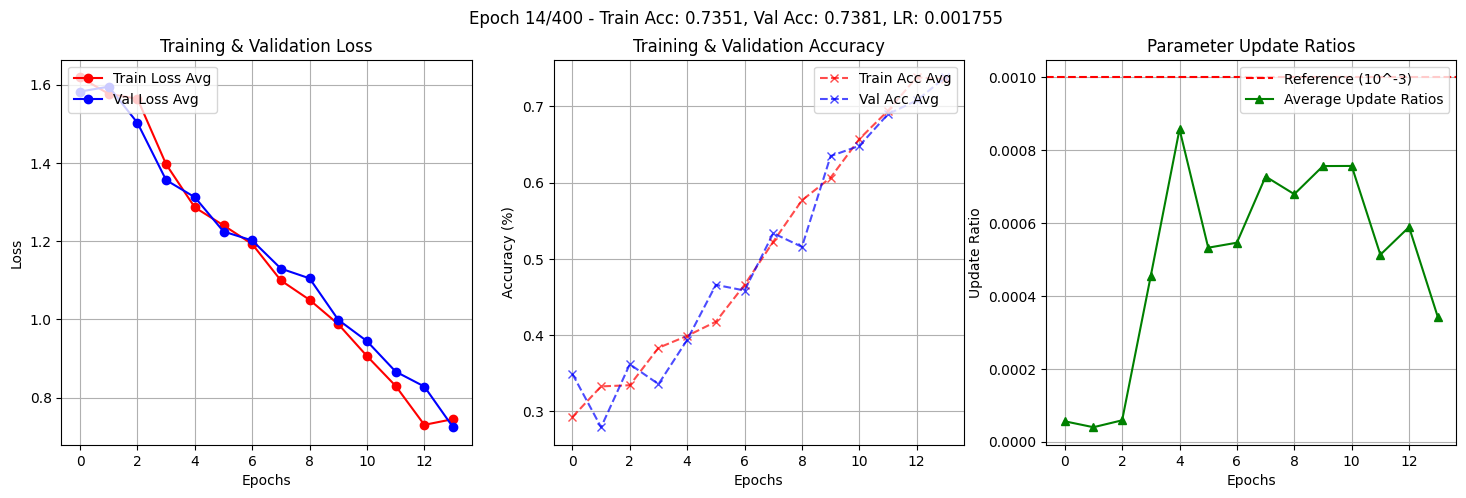

New best validation accuracy: 0.7812, saving model.
Stopping early due to lack of improvement in validation accuracy.


In [ ]:
# Data dictionary to track metrics
data_dict = {
    "tr_loss_avg": [],
    "vl_loss_avg": [],
    "tr_acc_avg": [],
    "vl_acc_avg": [],
    "avg_up_ratio": [],
}

for epoch in range(n_epoch):
    # Train
    tr_loss, tr_acc, avg_up_ratio = trainer(model, train_loader, criterion, optimizer, n_step, max_norm, device)
    data_dict["tr_loss_avg"].append(tr_loss)
    data_dict["tr_acc_avg"].append(tr_acc)
    data_dict["avg_up_ratio"].append(avg_up_ratio)

    # Validate
    vl_loss, vl_acc = validator(model, val_loader, criterion, n_step, device)
    data_dict["vl_loss_avg"].append(vl_loss)
    data_dict["vl_acc_avg"].append(vl_acc)

    # Early Stopping Check
    if (vl_acc - best_val_acc) > min_delta:
        best_val_acc = vl_acc
        patience_counter = patience  # Reset patience counter
        torch.save(model.state_dict(), best_model_path)  # Save the best model
        print(f"New best validation accuracy: {best_val_acc:.4f}, saving model.")
    else:
        patience_counter -= 1
        print(f"No improvement in validation accuracy. {patience_counter} epochs left until early stopping.")

    if patience_counter <= 0 or vl_acc > 0.78:
        print("Stopping early due to lack of improvement in validation accuracy.")
        break


    # Update the learning rate
    update_lr(optimizer, get_lr(epoch, lr, gamma, min_lr))

    # Plotting metrics
    new_lr = optimizer.param_groups[0]['lr']
    live_plot_triple(data_dict, title=f"Epoch {epoch + 1}/{n_epoch} - Train Acc: {tr_acc:.4f}, Val Acc: {vl_acc:.4f}, LR: {new_lr:.6f}")

### Test Our Model

In [ ]:
tester(model, test_loader, criterion, 200, device)


          Test Results Summary
Metric               |           Value
----------------------------------------
Average Loss         |          0.7064
Accuracy             |          76.49%
Precision            |          0.6478
Recall               |          0.6262
F1 Score             |          0.6044

Confusion Matrix:
------------------------------------------------------------
        0        1        2        3        4        5     
------------------------------------------------------------
0      472       0        3        39       25       12    
1       2        2        0        23       2        36    
2       20       0       154       17       3        71    
3       25       1        3       107       8        7     
4       39       0        1        43      567       7     
5       11       3        26       19       1       152    
------------------------------------------------------------
